# ML Project / NASDAQ Prediction and Analysis

**Objective** : Predicting if the Nasdaq-100 (^NDX) goes up or down during the New York session of a day (from the open to the close), using only the information available at the 9:30 ET open. Later the model will give this as a probability.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf
import requests 
import io
import os

In [2]:
path_to_data = ("./data")

## Data

We take the current Nasdaq-100 list from Wikipedia. This means we use today's companies for the whole period, so there's some survivorship bias (we'll mention it in the report).

In [3]:
html = requests.get("https://en.wikipedia.org/wiki/List_of_NASDAQ-100_companies", headers={"User-Agent": "Mozilla/5.0"}).text
table = pd.read_html(io.StringIO(html))
ndx = next(t for t in table if "Ticker" in t.columns)
TICKERS = ndx["Ticker"].str.replace(".", "-", regex=False).tolist()

In [4]:
TICKERS

['ADBE',
 'AMD',
 'ABNB',
 'ALNY',
 'GOOGL',
 'GOOG',
 'AMZN',
 'AEP',
 'AMGN',
 'ADI',
 'AAPL',
 'AMAT',
 'APP',
 'ARM',
 'ASML',
 'ALAB',
 'ADSK',
 'ADP',
 'AXON',
 'BKR',
 'BKNG',
 'AVGO',
 'CDNS',
 'CTAS',
 'CSCO',
 'CCEP',
 'CMCSA',
 'CEG',
 'CPRT',
 'CRWV',
 'COST',
 'CRWD',
 'CSX',
 'DDOG',
 'DXCM',
 'FANG',
 'DASH',
 'EXC',
 'FAST',
 'FER',
 'FTNT',
 'GEHC',
 'GILD',
 'HONA',
 'HON',
 'IDXX',
 'INTC',
 'INTU',
 'ISRG',
 'KDP',
 'KLAC',
 'LRCX',
 'LIN',
 'LITE',
 'MAR',
 'MRVL',
 'MELI',
 'META',
 'MCHP',
 'MU',
 'MSFT',
 'MSTR',
 'MRNA',
 'MDLZ',
 'MPWR',
 'MNST',
 'NBIS',
 'NFLX',
 'NVDA',
 'NXPI',
 'ORLY',
 'ODFL',
 'PCAR',
 'PLTR',
 'PANW',
 'PAYX',
 'PYPL',
 'PDD',
 'PEP',
 'QCOM',
 'REGN',
 'RKLB',
 'ROP',
 'ROST',
 'SNDK',
 'STX',
 'SHOP',
 'SPCX',
 'SBUX',
 'SNPS',
 'TMUS',
 'TTWO',
 'TER',
 'TSLA',
 'TXN',
 'TRI',
 'VRTX',
 'WMT',
 'WDC',
 'WDAY',
 'XEL']

On top of the stocks we add some macro data: volatility indices (VIX, VXN), treasury yields, oil, gold, silver, the dollar and Bitcoin. The idea is to give the model some context about the market, not just prices.

We also add the main Asian and European indices, the sessions that trade before (or during) the New York open.

In [5]:
NASDAQ_FEATURES = {
    # --- INDICES ET VOLATILITÉ ---                    
    "^IXIC": "Nasdaq_composite",              # Broad tech market index
    "^VXN": "Nasdaq_volatility",              # Nasdaq-100 implied volatility (Tech fear index)
    "^VIX": "Volatility",                     # S&P 500 implied volatility (Market fear index)

    # --- interest ---
    "^IRX": "3month_treasury_yield",          # 3-month Treasury yield
    "^FVX": "5y_treasury_yield",              # 5-year Treasury yield
    "^TNX": "10y_treasury_yield",             # 10-year Treasury yield (Tech discounting rate)
    "^TYX": "30y_treasury_yield",             # 30-year Treasury yield

    # --- MATIÈRES PREMIÈRES ET DEVISES ---
    "DX-Y.NYB": "US_dollar",                  # US dollar index (DXY)
    "CL=F": "crude_oil",                      # WTI crude oil futures
    "GC=F": "gold",                           # Gold futures
    "SI=F": "silver",                         # Silver futures
    "BTC-USD": "Bitcoin",                     # Bitcoin USD (Risk-on sentiment proxy)
}
tickers1 = list(NASDAQ_FEATURES.keys())

In [6]:
MACRO = {
    "^VIX": "Volatility",       # implied volatility (fear index)
    "^TNX": "10y_treasury_yield",       # 10-year Treasury yield
    "^IRX": "3month_treasury_yield",       # 3-month Treasury yield
    "CL=F": "crude_oil",       # WTI crude oil futures
    "DX-Y.NYB": "US_dollar",   # US dollar index
    "GC=F": "gold", 
    "SI=F": "silver",  # gold futures
}
tickers2 = list(MACRO.keys())

In [7]:
SESSIONS = {
    # --- Asia (closed before the NY open) ---
    "^N225": "Nikkei_225",
    "^HSI": "Hang_Seng",
    "^KS11": "KOSPI",
    "^AXJO": "ASX_200",

    # --- Europe (still open at the NY open) ---
    "^GDAXI": "DAX",
    "^FTSE": "FTSE_100",
    "^STOXX50E": "Euro_Stoxx_50",
}
tickers3 = list(SESSIONS.keys())

In [8]:
TICKERS = list(dict.fromkeys(TICKERS + tickers1 + tickers2 + tickers3))

In [9]:
df_nasdaq = yf.download("^NDX", start="2018-01-01", end="2026-09-30",
                     auto_adjust=True, progress=False)[['Open', 'Close','Volume']]
print(df_nasdaq.columns)
print(df_nasdaq.tail())

MultiIndex([(  'Open', '^NDX'),
            ( 'Close', '^NDX'),
            ('Volume', '^NDX')],
           names=['Price', 'Ticker'])
Price               Open         Close      Volume
Ticker              ^NDX          ^NDX        ^NDX
Date                                              
2026-09-23  30706.230469  30470.289062  8491740000
2026-09-24  30225.189453  30478.859375  8078820000
2026-09-25  30517.460938  30608.130859  7275260000
2026-09-28  30426.630859  30276.810547  7030730000
2026-09-29  30412.289062  30339.330078  7097250000


In [10]:
df_nasdaq.head(20)

Price,Open,Close,Volume
Ticker,^NDX,^NDX,^NDX
Date,,,
2018-01-02,6431.589844,6511.339844,1929700000
2018-01-03,6520.029785,6575.799805,2173130000
2018-01-04,6595.750000,6584.580078,2103220000
2018-01-05,6613.129883,6653.290039,2024000000
2018-01-08,6651.680176,6676.629883,2055010000
2018-01-09,6692.870117,6677.939941,2155810000
2018-01-10,6640.660156,6662.660156,2132430000
2018-01-11,6675.689941,6708.490234,2015170000


In [11]:
raw = yf.download(TICKERS, start="2018-01-01", end="2026-09-30")[['Open', 'Close','Volume']]

[                       0%                       ]

[*                      2%                       ]  2 of 120 completed

[*                      2%                       ]  3 of 120 completed

[*                      2%                       ]  3 of 120 completed

[**                     4%                       ]  5 of 120 completed

[**                     4%                       ]  5 of 120 completed

... (96 outputs left out)

[**********************97%********************** ]  116 of 120 completed

[**********************98%********************** ]  117 of 120 completed

[**********************98%********************** ]  118 of 120 completed

[*********************100%***********************]  120 of 120 completed

In [12]:
raw.head(10)

Price            Open                                                     \
Ticker           AAPL ABNB        ADBE        ADI        ADP        ADSK   
Date                                                                       
2018-01-01        NaN  NaN         NaN        NaN        NaN         NaN   
2018-01-02  39.741918  NaN  175.850006  76.266421  95.828752  105.339996   
2018-01-03  40.295440  NaN  178.000000  77.155241  95.952656  107.000000   
2018-01-04  40.297772  NaN  181.929993  78.514089  97.150192  110.129997   
2018-01-05  40.507968  NaN  185.000000  78.214945  97.910026  113.070000   
2018-01-06        NaN  NaN         NaN        NaN        NaN         NaN   
2018-01-07        NaN  NaN         NaN        NaN        NaN         NaN   
2018-01-08  40.720516  NaN  184.949997  78.462808  97.761355  110.419998   
2018-01-09  40.767233  NaN  185.570007  78.454255  97.241033  111.570000   
2018-01-10  40.442570  NaN  185.210007  77.838933  97.687038  111.709999   

Price                                              ...        Volume       \
Ticker            AEP ALAB        ALNY       AMAT  ...          ^HSI ^IRX   
Date                                               ...                      
2018-01-01        NaN  NaN         NaN        NaN  ...           NaN  NaN   
2018-01-02  53.872308  NaN  128.320007  47.025075  ...  2.442300e+09  0.0   
2018-01-03  53.158234  NaN  131.380005  48.717553  ...  2.309500e+09  0.0   
2018-01-04  52.768083  NaN  134.940002  49.591082  ...  2.995600e+09  0.0   
2018-01-05  52.355841  NaN  131.960007  49.727575  ...  2.263900e+09  0.0   
2018-01-06        NaN  NaN         NaN        NaN  ...           NaN  NaN   
2018-01-07        NaN  NaN         NaN        NaN  ...           NaN  NaN   
2018-01-08  52.142346  NaN  130.330002  50.055144  ...  2.004200e+09  0.0   
2018-01-09  52.488335  NaN  129.800003  51.110667  ...  2.004900e+09  0.0   
2018-01-10  51.759535  NaN  129.000000  49.218009  ...  2.595400e+09  0.0   

Price                                                                       \
Ticker             ^IXIC     ^KS11        ^N225   ^STOXX50E ^TNX ^TYX ^VIX   
Date                                                                         
2018-01-01           NaN       NaN          NaN         NaN  NaN  NaN  NaN   
2018-01-02  1.929700e+09  262200.0          NaN         NaN  0.0  0.0  0.0   
2018-01-03  2.173130e+09  331100.0          NaN  33320900.0  0.0  0.0  0.0   
2018-01-04  2.103220e+09  333800.0  102200000.0  43638600.0  0.0  0.0  0.0   
2018-01-05  2.024000e+09  308800.0  101900000.0  35418700.0  0.0  0.0  0.0   
2018-01-06           NaN       NaN          NaN         NaN  NaN  NaN  NaN   
2018-01-07           NaN       NaN          NaN         NaN  NaN  NaN  NaN   
2018-01-08  2.055010e+09  311400.0          NaN  28252700.0  0.0  0.0  0.0   
2018-01-09  2.155810e+09  374300.0   94100000.0  31607400.0  0.0  0.0  0.0   
2018-01-10  2.132430e+09  444000.0   88800000.0  53970300.0  0.0  0.0  0.0   

Price            
Ticker     ^VXN  
Date             
2018-01-01  NaN  
2018-01-02  0.0  
2018-01-03  0.0  
2018-01-04  0.0  
2018-01-05  0.0  
2018-01-06  NaN  
2018-01-07  NaN  
2018-01-08  0.0  
2018-01-09  0.0  
2018-01-10  0.0  

[10 rows x 360 columns]

We join everything on the Nasdaq-100 dates (inner join). Bitcoin trades on weekends but the index doesn't, so this way we only keep real trading days.

The other markets have different holidays, so after the join we forward-fill (never backward fill) only the macro and other-session columns: on those days they just keep their last known value.

In [13]:
raw = pd.concat((df_nasdaq,raw),axis=1,join='inner',)

In [14]:
other = list(dict.fromkeys(tickers1 + tickers2 + tickers3))
other_cols = raw.columns.get_level_values(1).isin(other)
raw.loc[:, other_cols] = raw.loc[:, other_cols].ffill()

In [15]:
raw.loc[:, (slice(None), 'BTC-USD')]

Price,Open,Close,Volume
Ticker,BTC-USD,BTC-USD,BTC-USD
Date,,,
2018-01-02,13625.000000,14982.099609,16846600192
2018-01-03,14978.200195,15201.000000,16871900160
2018-01-04,15270.700195,15599.200195,21783199744
2018-01-05,15477.200195,17429.500000,23840899072
2018-01-08,16476.199219,15170.099609,18413899776
...,...,...,...
2026-09-23,86176.765625,84383.007812,46088463341
2026-09-24,84381.593750,84379.062500,37106744985


### Missing values

Some companies are very recent (ARM, CRWV, SNDK...), so they have almost no history. We drop the columns with less than 40% of data. We picked this threshold by looking at which columns were left.

We also drop GOOG (almost the same as GOOGL) and ^IXIC (it moves with the Nasdaq-100), they don't add anything new.

In [16]:
dropping = raw.isnull().sum().sort_values(ascending=False)/len(raw)

In [17]:
dropping

Price   Ticker
Volume  HONA      0.966318
Open    HONA      0.966318
Close   HONA      0.966318
        SPCX      0.965863
Volume  SPCX      0.965863
                    ...   
        PAYX      0.000000
        PANW      0.000000
        ORLY      0.000000
        ODFL      0.000000
        TTWO      0.000000
Length: 363, dtype: float64

In [18]:
raw_drop = raw.dropna(axis=1, thresh=int(0.4 * len(raw)))
# GOOG is basically GOOGL and ^IXIC moves with ^NDX, so they add nothing
raw_drop = raw_drop.drop(columns=["GOOG", "^IXIC"], level=1)

In [19]:
print(list(set(raw.columns.tolist()) - set(raw_drop.columns.tolist())))

[('Volume', 'ARM'), ('Close', 'GOOG'), ('Volume', '^IXIC'), ('Open', 'HONA'), ('Volume', 'HONA'), ('Close', 'ARM'), ('Open', 'CRWV'), ('Open', 'ALAB'), ('Open', 'SNDK'), ('Open', 'SPCX'), ('Open', 'NBIS'), ('Close', '^IXIC'), ('Volume', 'ALAB'), ('Volume', 'CRWV'), ('Volume', 'SNDK'), ('Volume', 'SPCX'), ('Open', 'GOOG'), ('Close', 'HONA'), ('Volume', 'NBIS'), ('Volume', 'GOOG'), ('Close', 'CRWV'), ('Close', 'ALAB'), ('Close', 'SNDK'), ('Open', 'ARM'), ('Close', 'SPCX'), ('Close', 'NBIS'), ('Open', '^IXIC')]


In [20]:
try:
    raw_drop.loc[:, (slice(None), "SPCX")]
except KeyError:
    print("SPCX not in raw_drop: it was dropped")

SPCX not in raw_drop: it was dropped


In [21]:
raw.loc[:, (slice(None), "SPCX")]

Price,Open,Close,Volume
Ticker,SPCX,SPCX,SPCX
Date,,,
2018-01-02,NaN,NaN,NaN
2018-01-03,NaN,NaN,NaN
2018-01-04,NaN,NaN,NaN
2018-01-05,NaN,NaN,NaN
2018-01-08,NaN,NaN,NaN
...,...,...,...
2026-09-23,153.279999,148.360001,60641600.0
2026-09-24,148.199997,148.029999,72721400.0


In [22]:
raw_drop.describe()

Price           Open         Close        Volume         Open               \
Ticker          ^NDX          ^NDX          ^NDX         AAPL         ABNB   
count    2197.000000   2197.000000  2.197000e+03  2197.000000  1456.000000   
mean    14677.919086  14681.546265  5.123673e+09   148.031545   138.414857   
std      6370.406766   6370.727726  2.500686e+09    77.166099    23.576950   
min      5969.080078   5899.350098  9.589500e+08    34.132257    82.970001   
25%      8865.580078   8848.519531  3.325270e+09    71.167153   122.510002   
50%     13608.950195  13603.959961  4.738880e+09   146.823447   135.340004   
75%     18992.580078  19021.189453  6.407180e+09   199.635155   150.787502   
max     30730.109375  30732.400391  1.828615e+10   341.079987   216.240005   

Price                                                                    ...  \
Ticker         ADBE          ADI          ADP         ADSK          AEP  ...   
count   2197.000000  2197.000000  2197.000000  2197.000000  2197.000000  ...   
mean     394.026363   165.933222   192.065332   222.374178    79.982987  ...   
std      123.324660    77.787196    58.292472    57.058879    20.381231  ...   
min      175.850006    67.266362    90.328288   105.339996    47.076852  ...   
25%      279.579987   102.157907   138.211590   179.309998    67.831508  ...   
50%      376.369995   153.893840   198.416306   219.429993    74.400123  ...   
75%      492.320007   202.949742   232.324176   269.760010    88.113281  ...   
max      696.280029   436.420331   316.343099   342.519989   137.979509  ...   

Price         Volume                                                    \
Ticker        ^GDAXI          ^HSI    ^IRX         ^KS11         ^N225   
count   2.197000e+03  2.197000e+03  2197.0  2.197000e+03  2.195000e+03   
mean    7.744324e+07  2.483036e+09     0.0  6.136807e+05  9.529021e+07   
std     3.448088e+07  1.040478e+09     0.0  3.237849e+05  3.878606e+07   
min     0.000000e+00  4.840000e+08     0.0  0.000000e+00  0.000000e+00   
25%     5.697320e+07  1.765800e+09     0.0  4.027000e+05  6.670000e+07   
50%     6.993570e+07  2.265000e+09     0.0  5.170000e+05  8.390000e+07   
75%     8.843790e+07  2.978600e+09     0.0  7.162000e+05  1.168000e+08   
max     4.001654e+08  1.268650e+10     0.0  3.455500e+06  2.951000e+08   

Price                                                 
Ticker     ^STOXX50E    ^TNX    ^TYX    ^VIX    ^VXN  
count   2.196000e+03  2197.0  2197.0  2197.0  2197.0  
mean    3.287606e+07     0.0     0.0     0.0     0.0  
std     1.546477e+07     0.0     0.0     0.0     0.0  
min     0.000000e+00     0.0     0.0     0.0     0.0  
25%     2.322765e+07     0.0     0.0     0.0     0.0  
50%     2.998370e+07     0.0     0.0     0.0     0.0  
75%     3.806618e+07     0.0     0.0     0.0     0.0  
max     1.673299e+08     0.0     0.0     0.0     0.0  

[8 rows x 336 columns]

In [23]:
from fastai.tabular.all import add_datepart

raw_drop = raw_drop.reset_index()
raw_time = add_datepart(raw_drop, 'Date', drop=False)
# Year and Elapsed are just time trends
raw_time = raw_time.drop(columns=["Year", "Elapsed"])

C:\Users\salva\Desktop\Uni\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


C:\Users\salva\AppData\Local\Temp\ipykernel_22836\3794246381.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  raw_drop = raw_drop.reset_index()
C:\Users\salva\Desktop\Uni\.venv\Lib\site-packages\fastai\tabular\core.py:38: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  for n in attr: df[prefix + n] = getattr(field.dt, n.lower()) if n != 'Week' else week
C:\Users\salva\Desktop\Uni\.venv\Lib\site-packages\fastai\tabular\core.py:38: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.i

In [24]:
raw_time.isnull().sum().sort_values(ascending=False)/len(raw)

Price          Ticker
Open           GEHC      0.568047
Close          GEHC      0.568047
Volume         GEHC      0.568047
Open           CEG       0.463814
Close          CEG       0.463814
                           ...   
Volume         ^VXN      0.000000
               VRTX      0.000000
               TXN       0.000000
               TTWO      0.000000
Is_year_start            0.000000
Length: 348, dtype: float64

In [25]:
columns = raw_time.columns.to_list()
print(columns)

[('Date', ''), ('Open', '^NDX'), ('Close', '^NDX'), ('Volume', '^NDX'), ('Open', 'AAPL'), ('Open', 'ABNB'), ('Open', 'ADBE'), ('Open', 'ADI'), ('Open', 'ADP'), ('Open', 'ADSK'), ('Open', 'AEP'), ('Open', 'ALNY'), ('Open', 'AMAT'), ('Open', 'AMD'), ('Open', 'AMGN'), ('Open', 'AMZN'), ('Open', 'APP'), ('Open', 'ASML'), ('Open', 'AVGO'), ('Open', 'AXON'), ('Open', 'BKNG'), ('Open', 'BKR'), ('Open', 'BTC-USD'), ('Open', 'CCEP'), ('Open', 'CDNS'), ('Open', 'CEG'), ('Open', 'CL=F'), ('Open', 'CMCSA'), ('Open', 'COST'), ('Open', 'CPRT'), ('Open', 'CRWD'), ('Open', 'CSCO'), ('Open', 'CSX'), ('Open', 'CTAS'), ('Open', 'DASH'), ('Open', 'DDOG'), ('Open', 'DX-Y.NYB'), ('Open', 'DXCM'), ('Open', 'EXC'), ('Open', 'FANG'), ('Open', 'FAST'), ('Open', 'FER'), ('Open', 'FTNT'), ('Open', 'GC=F'), ('Open', 'GEHC'), ('Open', 'GILD'), ('Open', 'GOOGL'), ('Open', 'HON'), ('Open', 'IDXX'), ('Open', 'INTC'), ('Open', 'INTU'), ('Open', 'ISRG'), ('Open', 'KDP'), ('Open', 'KLAC'), ('Open', 'LIN'), ('Open', 'LITE

In [26]:
raw_time = raw_time.copy(True)

In [27]:
raw_time.loc[:, (slice(None),'^NDX')]

Price,Open,Close,Volume
Ticker,^NDX,^NDX,^NDX
0,6431.589844,6511.339844,1929700000
1,6520.029785,6575.799805,2173130000
2,6595.750000,6584.580078,2103220000
3,6613.129883,6653.290039,2024000000
4,6651.680176,6676.629883,2055010000
...,...,...,...
2192,30706.230469,30470.289062,8491740000
2193,30225.189453,30478.859375,8078820000
2194,30517.460938,30608.130859,7275260000


## Target

We decide at the 9:30 ET open of day `t`, buy at the open of `t` and sell at the close of `t` (the New York session).

We use the log return, and the label is 1 if the return is positive, 0 if not.

In [28]:
ndx = raw_drop.set_index('Date')
close = ndx['Close']['^NDX']
open_ = ndx['Open']['^NDX']

In [29]:
open_

Date
2018-01-02     6431.589844
2018-01-03     6520.029785
2018-01-04     6595.750000
2018-01-05     6613.129883
2018-01-08     6651.680176
                  ...     
2026-09-23    30706.230469
2026-09-24    30225.189453
2026-09-25    30517.460938
2026-09-28    30426.630859
2026-09-29    30412.289062
Name: ^NDX, Length: 2197, dtype: float64

In [30]:
ret_ny = np.log(close / open_)

In [31]:
ret_ny

Date
2018-01-02    0.012323
2018-01-03    0.008517
2018-01-04   -0.001695
2018-01-05    0.006054
2018-01-08    0.003744
                ...   
2026-09-23   -0.007714
2026-09-24    0.008358
2026-09-25    0.002967
2026-09-28   -0.004936
2026-09-29   -0.002402
Name: ^NDX, Length: 2197, dtype: float64

In [32]:
raw_time = raw_time.set_index("Date")

In [33]:
raw_time

Price               Open         Close      Volume        Open              \
Ticker              ^NDX          ^NDX        ^NDX        AAPL        ABNB   
Date                                                                         
2018-01-02   6431.589844   6511.339844  1929700000   39.741918         NaN   
2018-01-03   6520.029785   6575.799805  2173130000   40.295440         NaN   
2018-01-04   6595.750000   6584.580078  2103220000   40.297772         NaN   
2018-01-05   6613.129883   6653.290039  2024000000   40.507968         NaN   
2018-01-08   6651.680176   6676.629883  2055010000   40.720516         NaN   
...                  ...           ...         ...         ...         ...   
2026-09-23  30706.230469  30470.289062  8491740000  341.079987  159.520004   
2026-09-24  30225.189453  30478.859375  8078820000  336.720001  150.699997   
2026-09-25  30517.460938  30608.130859  7275260000  336.040009  152.175003   
2026-09-28  30426.630859  30276.810547  7030730000  340.369995  155.940002   
2026-09-29  30412.289062  30339.330078  7097250000  336.970001  156.095001   

Price                                                                   ...  \
Ticker            ADBE         ADI         ADP        ADSK         AEP  ...   
Date                                                                    ...   
2018-01-02  175.850006   76.266421   95.828752  105.339996   53.872308  ...   
2018-01-03  178.000000   77.155241   95.952656  107.000000   53.158234  ...   
2018-01-04  181.929993   78.514089   97.150192  110.129997   52.768083  ...   
2018-01-05  185.000000   78.214945   97.910026  113.070000   52.355841  ...   
2018-01-08  184.949997   78.462808   97.761355  110.419998   52.142346  ...   
...                ...         ...         ...         ...         ...  ...   
2026-09-23  239.479996  388.950012  268.540009  220.020004  119.879997  ...   
2026-09-24  241.669998  381.209991  264.850006  217.479996  118.400002  ...   
2026-09-25  238.850006  381.529999  261.890015  211.350006  117.529999  ...   
2026-09-28  229.720001  395.450012  260.899994  206.960007  118.050003  ...   
2026-09-29  230.990005  401.619995  259.700012  204.649994  117.500000  ...   

Price      Week Day Dayofweek Dayofyear Is_month_end Is_month_start  \
Ticker                                                                
Date                                                                  
2018-01-02    1   2         1         2        False          False   
2018-01-03    1   3         2         3        False          False   
2018-01-04    1   4         3         4        False          False   
2018-01-05    1   5         4         5        False          False   
2018-01-08    2   8         0         8        False          False   
...         ...  ..       ...       ...          ...            ...   
2026-09-23   39  23         2       266        False          False   
2026-09-24   39  24         3       267        False          False   
2026-09-25   39  25         4       268        False          False   
2026-09-28   40  28         0       271        False          False   
2026-09-29   40  29         1       272        False          False   

Price      Is_quarter_end Is_quarter_start Is_year_end Is_year_start  
Ticker                                                                
Date                                                                  
2018-01-02          False            False       False         False  
2018-01-03          False            False       False         False  
2018-01-04          False            False       False         False  
2018-01-05          False            False       False         False  
2018-01-08          False            False       False         False  
...                   ...              ...         ...           ...  
2026-09-23          False            False       False         False  
2026-09-24          False            False       False         False  
2026-09-25          Fals

In [34]:
data = raw_time.copy()
# both have the Date index, so pandas aligns them by date
data["ret_ny"] = ret_ny

In [35]:
r = data["ret_ny"]
data["y_ny"] = (r > 0).astype(float).where(r.notna())

target_cols = [("ret_ny", ""), ("y_ny", "")]

In [36]:
print(data[["ret_ny", "y_ny"]].tail(7))

Price         ret_ny y_ny
Ticker                   
Date                     
2026-09-21  0.017713  1.0
2026-09-22  0.007708  1.0
2026-09-23 -0.007714  0.0
2026-09-24  0.008358  1.0
2026-09-25  0.002967  1.0
2026-09-28 -0.004936  0.0
2026-09-29 -0.002402  0.0


In [37]:
print(data.columns.tolist())
print(data.index.min(), data.index.max(), len(data))

[('Open', '^NDX'), ('Close', '^NDX'), ('Volume', '^NDX'), ('Open', 'AAPL'), ('Open', 'ABNB'), ('Open', 'ADBE'), ('Open', 'ADI'), ('Open', 'ADP'), ('Open', 'ADSK'), ('Open', 'AEP'), ('Open', 'ALNY'), ('Open', 'AMAT'), ('Open', 'AMD'), ('Open', 'AMGN'), ('Open', 'AMZN'), ('Open', 'APP'), ('Open', 'ASML'), ('Open', 'AVGO'), ('Open', 'AXON'), ('Open', 'BKNG'), ('Open', 'BKR'), ('Open', 'BTC-USD'), ('Open', 'CCEP'), ('Open', 'CDNS'), ('Open', 'CEG'), ('Open', 'CL=F'), ('Open', 'CMCSA'), ('Open', 'COST'), ('Open', 'CPRT'), ('Open', 'CRWD'), ('Open', 'CSCO'), ('Open', 'CSX'), ('Open', 'CTAS'), ('Open', 'DASH'), ('Open', 'DDOG'), ('Open', 'DX-Y.NYB'), ('Open', 'DXCM'), ('Open', 'EXC'), ('Open', 'FANG'), ('Open', 'FAST'), ('Open', 'FER'), ('Open', 'FTNT'), ('Open', 'GC=F'), ('Open', 'GEHC'), ('Open', 'GILD'), ('Open', 'GOOGL'), ('Open', 'HON'), ('Open', 'IDXX'), ('Open', 'INTC'), ('Open', 'INTU'), ('Open', 'ISRG'), ('Open', 'KDP'), ('Open', 'KLAC'), ('Open', 'LIN'), ('Open', 'LITE'), ('Open', '

## Features

Anything that trades in the US on day `t` is only known after the close, so we shift all the feature columns by 1 day: the row of day `t` only has data up to the close of `t-1`.

Some things are already known before the 9:30 ET open of day `t`, so we don't shift them:
- the open of the Nasdaq-100 of day `t`
- the open and close of the Asian indices of day `t` (they close before New York opens)
- the date columns from `add_datepart`

Europe is still open when New York opens, so the European indices stay shifted. We also add the opening gap of the Nasdaq-100: `log(Open_t / Close_{t-1})`.

In [38]:
ASIA = ["^N225", "^HSI", "^KS11", "^AXJO"]
not_shifted = [("Open", "^NDX")] + [(p, t) for p in ("Open", "Close") for t in ASIA]

shifted = [c for c in data.columns if c[1] != "" and c not in not_shifted]
data[shifted] = data[shifted].shift(1)

In [39]:
data["gap_ndx"] = np.log(open_ / close.shift(1))

C:\Users\salva\AppData\Local\Temp\ipykernel_22836\3047973942.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  data["gap_ndx"] = np.log(open_ / close.shift(1))


In [40]:
# the close of day t must never be a feature
X = data.drop(columns=target_cols)
assert not any(X[c].equals(close) for c in X.columns)

The rows without a target are removed.

In [41]:
data = data.dropna(subset=[("y_ny", "")])

In [42]:
data.to_feather("data/final_data_ny.feather")

In [43]:
from sklearn.model_selection import TimeSeriesSplit

## Train / test split

The test set starts in July 2025 and we don't touch it until the end.

The target only uses prices of day `t`, so it doesn't look ahead anymore. A gap of 1 row between train and test (and in `TimeSeriesSplit`) is enough.

In [44]:
TEST_START = "2025-07-01"
train = data.loc[:"2025-06-30"]
test = data.loc[TEST_START:]

In [45]:
gap = 1
train = train.iloc[:-gap]

In [46]:
print("train:", train.index.min(), "->", train.index.max(), train.shape)
print("test: ", test.index.min(), "->", test.index.max(), test.shape)

train: 2018-01-02 00:00:00 -> 2025-06-27 00:00:00 (1882, 350)
test:  2025-07-01 00:00:00 -> 2026-09-29 00:00:00 (314, 350)


In [47]:
test.to_feather("data/test_holdout_ny.feather")

In [48]:
tscv = TimeSeriesSplit(n_splits=5, gap=gap)
X_train = train.drop(columns=target_cols)
y_train = train[[("y_ny", "")]]

Class balance: in train the market goes up during the New York session 54% of the days. So a model that always says "up" already gets that accuracy, that's the baseline to beat.

In [49]:
y_train.describe()

Price,y_ny
Ticker,
count,1882.000000
mean,0.541977
std,0.498367
min,0.000000
25%,0.000000
50%,1.000000
75%,1.000000
max,1.000000


## EDA (only on train)

The NY-session returns have fat tails (kurtosis around 5.9) and are almost symmetric (skew 0.06). The mean is very small, about 0.03% per day, with a daily std of 1.2%.

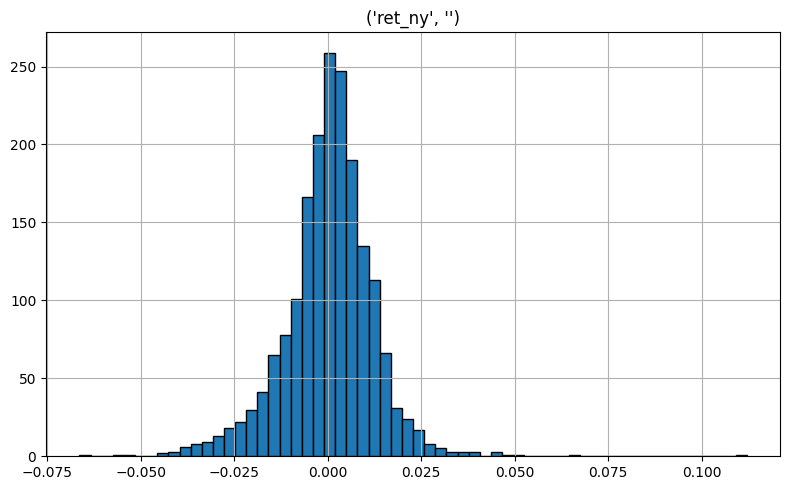

In [50]:
train[[("ret_ny", "")]].hist(bins=60, figsize=(8, 5), edgecolor="black")
plt.tight_layout()
plt.show()

In [51]:
train[[("ret_ny", "")]].kurtosis()

Price   Ticker
ret_ny            5.890686
dtype: float64

In [52]:
train[[("ret_ny", "")]].skew()

Price   Ticker
ret_ny            0.06257
dtype: float64

### Volatility

Realized volatility (21 days, annualized) with past close-to-close returns, compared with the VXN (implied volatility). Here we use the original (not shifted) Nasdaq-100 closes. The VXN is usually a bit higher (24% vs 22% on average) and both jump in the stress periods like 2020 and 2022.

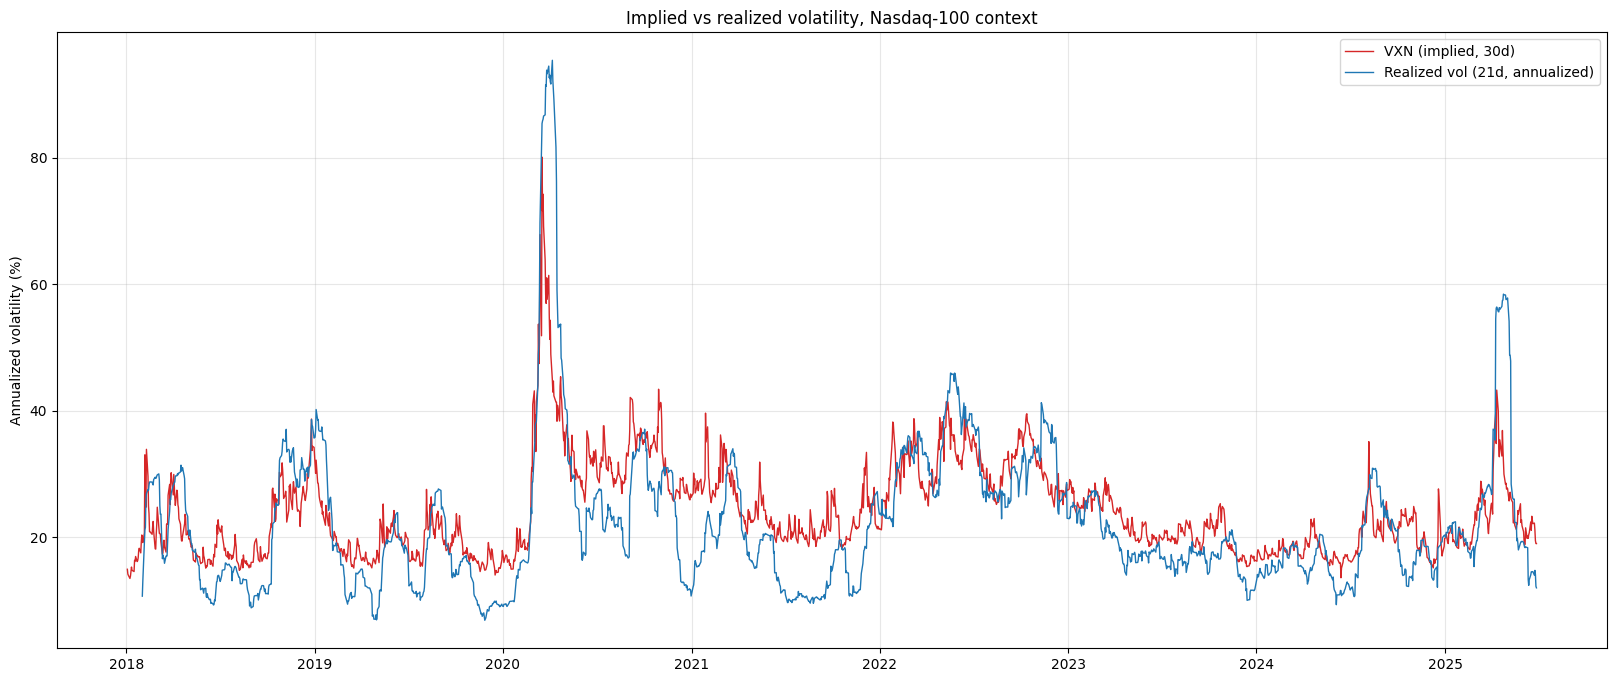

In [53]:
# past close-to-close returns, so the value at t only uses data up to the close of t
# unshifted closes from df_nasdaq, only on the train dates
ndx_close = df_nasdaq[("Close", "^NDX")].loc[train.index]
ndx_ret = np.log(ndx_close).diff()
vol_21d = ndx_ret.rolling(21).std()*np.sqrt(252)*100
vxn = train[("Close", "^VXN")]

fig, ax = plt.subplots(figsize=(20,8))

ax.plot(vxn.index, vxn.values, label="VXN (implied, 30d)", color="tab:red", linewidth=1)
ax.plot(vol_21d.index, vol_21d.values, label="Realized vol (21d, annualized)",color="tab:blue", linewidth=1)

ax.set_title("Implied vs realized volatility, Nasdaq-100 context")
ax.set_ylabel("Annualized volatility (%)")
ax.legend()
ax.grid(alpha=0.3)

plt.show()

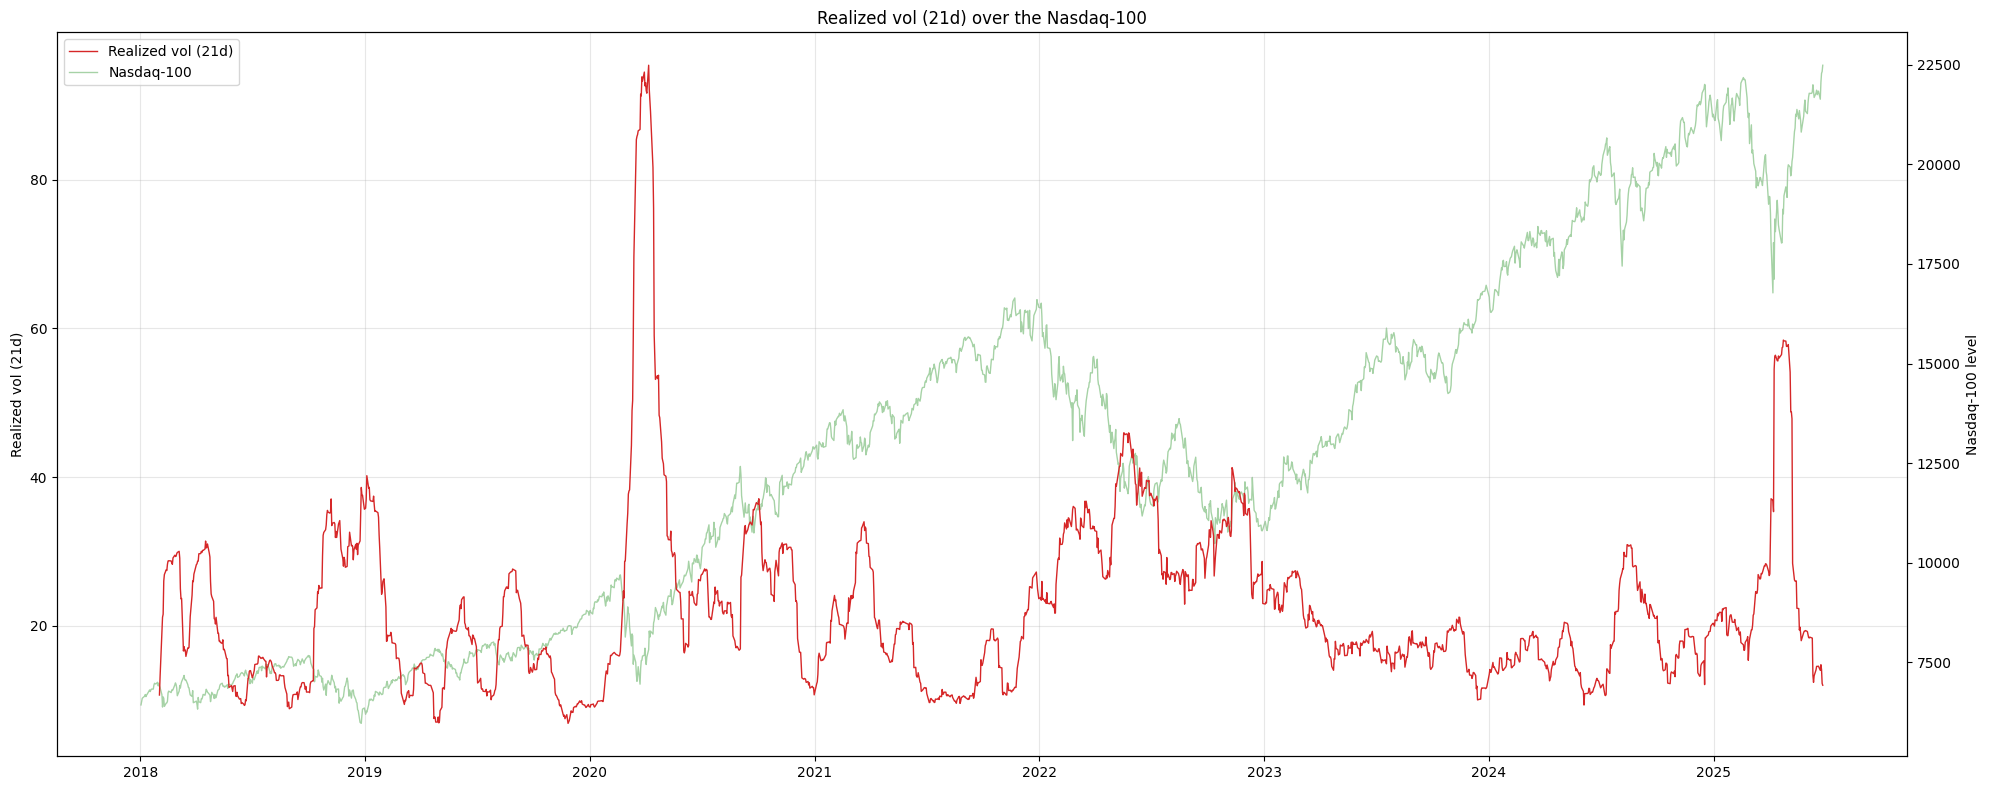

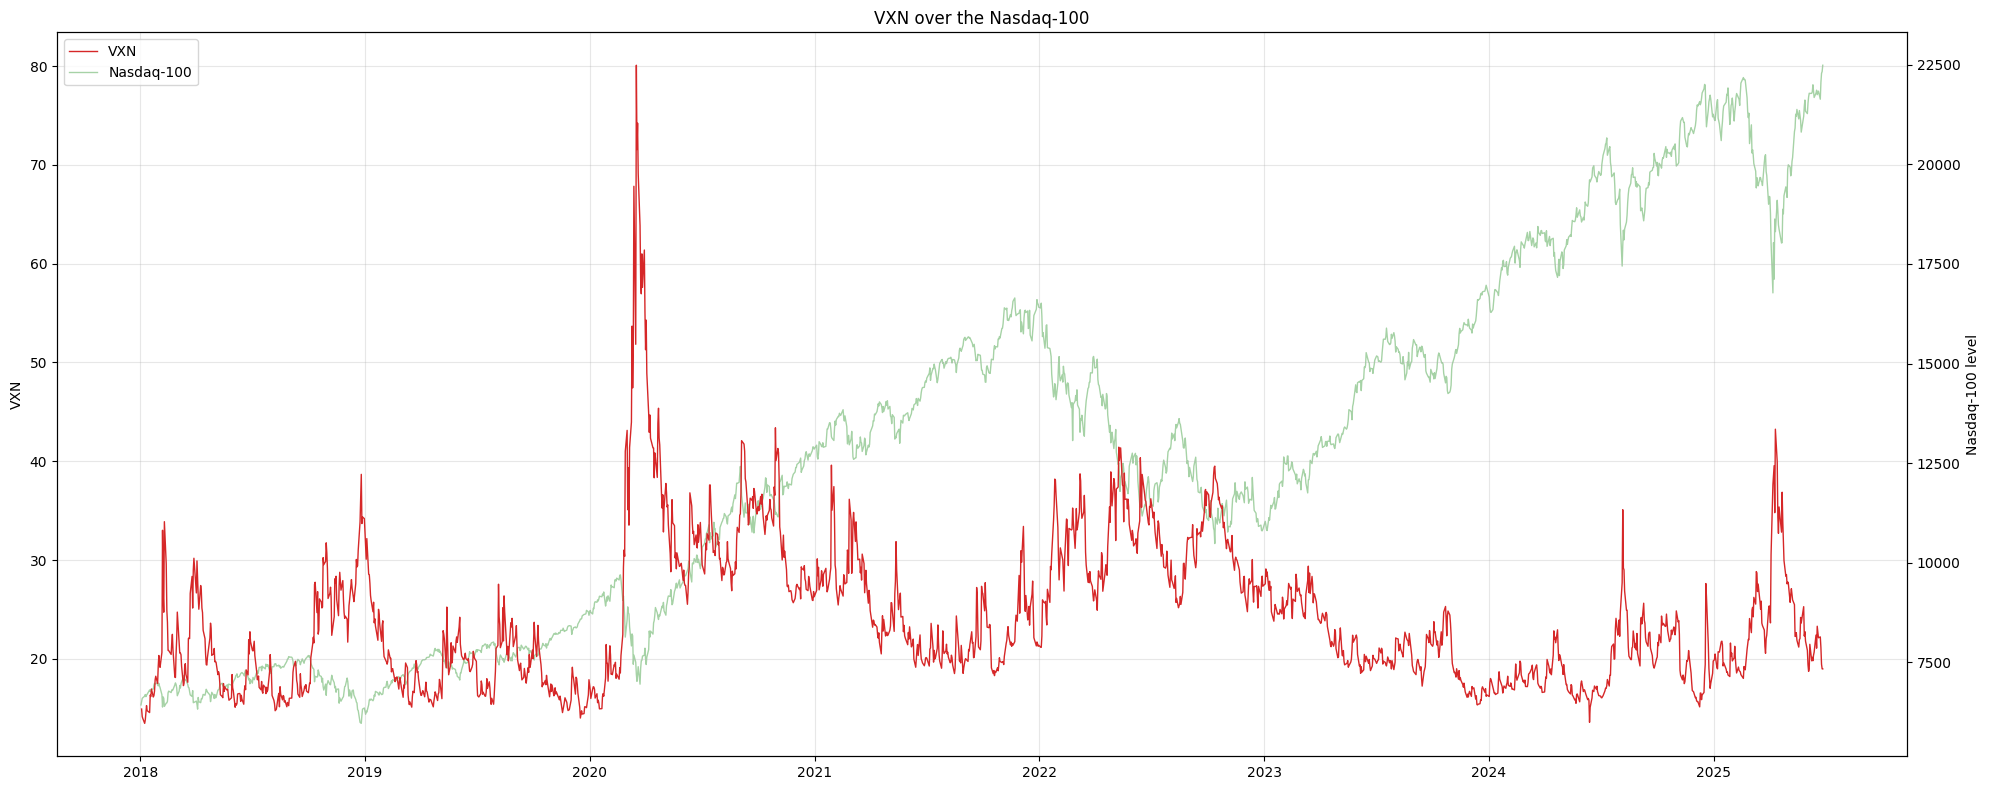

In [54]:
volatility = {"Realized vol (21d)": vol_21d, "VXN": vxn}
nasdaq = df_nasdaq['Open','^NDX']

for name, vol in volatility.items():
    nasdaq1 = nasdaq.loc[vol.index]
    fig, ax1 = plt.subplots(figsize=(20,8))

    ax2 = ax1.twinx()
    ax2.plot(nasdaq1.index, nasdaq1.values, color="green", alpha=0.35, linewidth=1, label="Nasdaq-100")
    ax2.set_ylabel("Nasdaq-100 level")
    ax2.set_zorder(ax1.get_zorder() - 1)   
    ax1.patch.set_visible(False) 

    ax1.plot(vol.index, vol.values, color="tab:red", linewidth=1, label=name)
    ax1.set_ylabel(name)
    ax1.set_title(f"{name} over the Nasdaq-100")

    lines = ax1.get_lines() + ax2.get_lines()
    ax1.legend(lines, [l.get_label() for l in lines], loc="upper left")

    ax1.grid(alpha=0.3)
    plt.tight_layout()

plt.show()



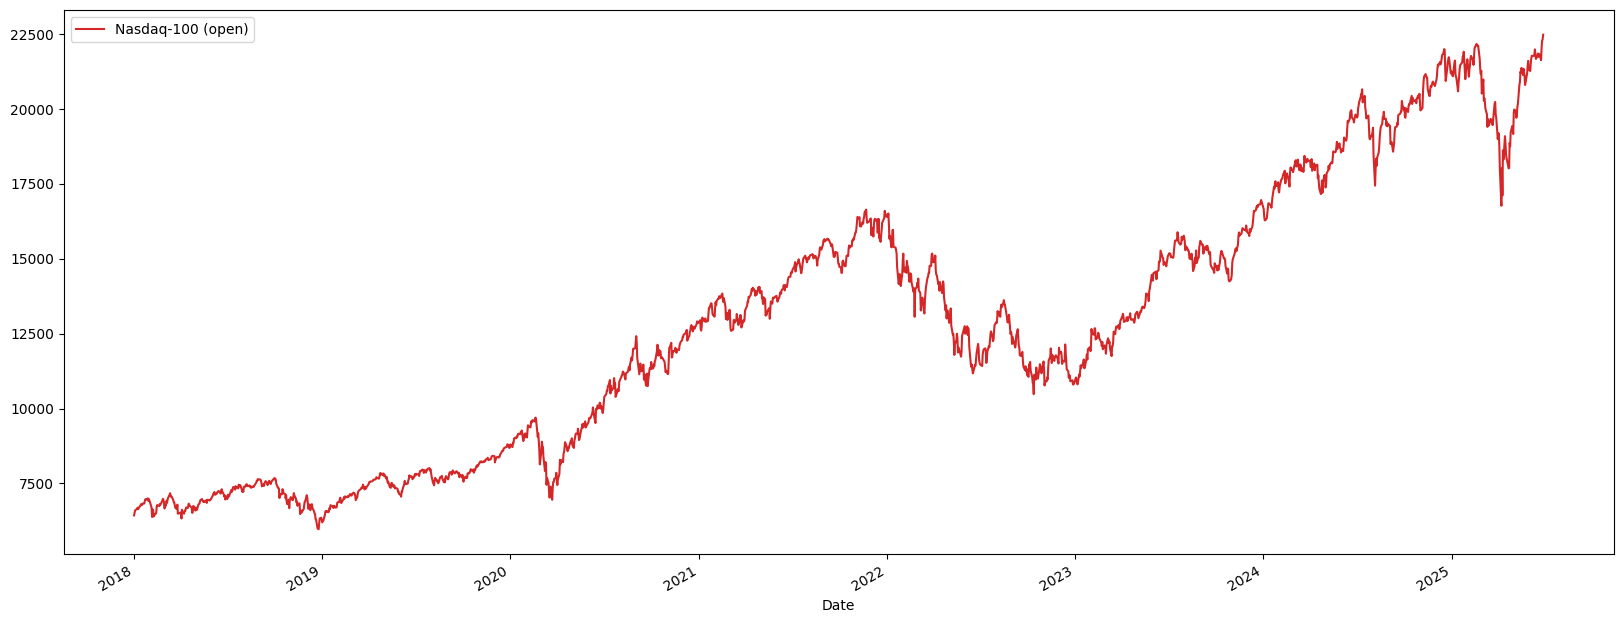

In [55]:
nasdaq.loc[train.index].plot(figsize=(20, 8), color="tab:red", label="Nasdaq-100 (open)")
plt.legend()